# Detecção de anomalias em séries temporais com Prophet e SARIMAX

**Objetivo:** detectar automaticamente picos e quedas fora do normal no volume horário de transações de um app de pagamentos, sem gerar alarme falso nos picos que já são esperados.

**Dados:** série **sintética** de 120 dias, com sazonalidade diária, semanal, tendência e anomalias injetadas no último mês (`src/gerar_serie.py`). Nenhum dado real é usado.

**Ideia central:** aprender o comportamento normal e alertar quando o valor observado sai do intervalo previsto.

**Roteiro**
1. Entender a série e suas sazonalidades
2. Baseline: limite fixo (média + 3 desvios padrão)
3. Prophet com intervalo de previsão
4. SARIMAX com termos de Fourier para as sazonalidades
5. Comparar a detecção com precision e recall

In [1]:
import sys; sys.path.insert(0, 'src')
import warnings, logging; warnings.filterwarnings('ignore')
logging.getLogger('prophet.plot').disabled = True
for nome in ['cmdstanpy', 'prophet']: logging.getLogger(nome).setLevel(logging.ERROR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gerar_serie import gerar_serie
from prophet import Prophet
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import precision_score, recall_score, f1_score
plt.rcParams['figure.figsize'] = (12, 3.5)
df = gerar_serie()
corte = df['ds'].max() - pd.Timedelta(days=30)
treino, teste = df[df['ds'] <= corte].copy(), df[df['ds'] > corte].copy()
print(f"Treino: {len(treino)} horas | Teste: {len(teste)} horas | horas anômalas no teste: {teste['anomalia'].sum()}")

Treino: 2160 horas | Teste: 720 horas | horas anômalas no teste: 17


## 1. A série

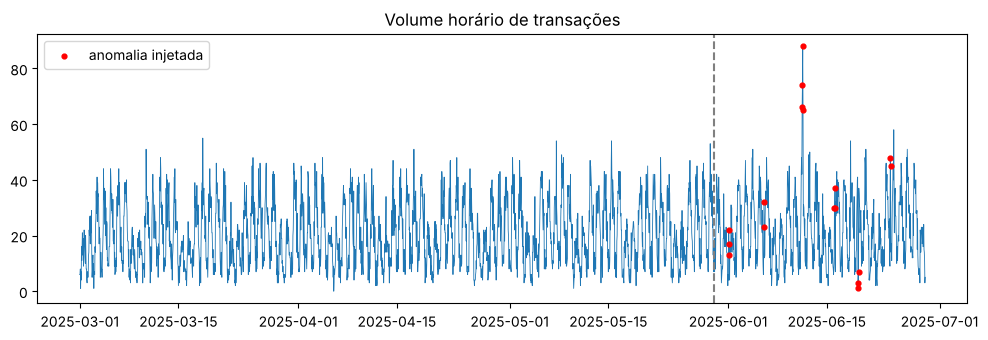

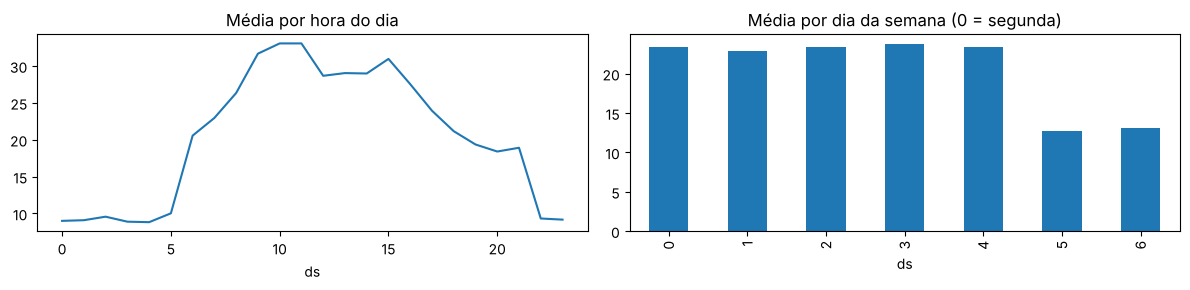

In [2]:
fig, ax = plt.subplots()
ax.plot(df['ds'], df['y'], lw=0.6); ax.set_title('Volume horário de transações')
an = df[df['anomalia'] == 1]
ax.scatter(an['ds'], an['y'], c='red', s=12, label='anomalia injetada', zorder=3)
ax.axvline(corte, c='gray', ls='--'); ax.legend(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
treino.groupby(treino['ds'].dt.hour)['y'].mean().plot(ax=ax[0], title='Média por hora do dia')
treino.groupby(treino['ds'].dt.dayofweek)['y'].mean().plot.bar(ax=ax[1], title='Média por dia da semana (0 = segunda)')
plt.tight_layout(); plt.show()

**Leitura:** o volume tem dois picos diários, cai muito de madrugada e no fim de semana, e cresce levemente com o tempo. Um limite fixo não consegue respeitar esse padrão.

## 2. Baseline: limite fixo

In [3]:
lim_sup = treino['y'].mean() + 3 * treino['y'].std()
lim_inf = max(treino['y'].mean() - 3 * treino['y'].std(), 0)
teste['alerta_fixo'] = ((teste['y'] > lim_sup) | (teste['y'] < lim_inf)).astype(int)
print(f"Limite superior fixo: {lim_sup:.1f} | inferior: {lim_inf:.1f}")

Limite superior fixo: 54.1 | inferior: 0.0


## 3. Prophet

In [4]:
m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False, interval_width=0.99)
m.fit(treino[['ds', 'y']])
prev_p = m.predict(teste[['ds']])
teste['yhat_prophet'] = prev_p['yhat'].values
teste['inf_prophet'], teste['sup_prophet'] = prev_p['yhat_lower'].values, prev_p['yhat_upper'].values
teste['alerta_prophet'] = ((teste['y'] > teste['sup_prophet']) | (teste['y'] < teste['inf_prophet'])).astype(int)

## 4. SARIMAX com termos de Fourier
A sazonalidade diária (24 h) e a semanal (168 h) entram como variáveis externas de seno e cosseno. Isso deixa o modelo leve e captura as duas sazonalidades ao mesmo tempo.

Como é uma contagem, a variância cresce com o volume. Aplico **raiz quadrada** na série para estabilizar a variância antes de ajustar o modelo e volto para a escala original no fim. Sem essa transformação, o intervalo fica largo demais nas horas calmas e o modelo perde a maioria das anomalias.

In [5]:
def fourier(idx, periodo, k):
    t = np.arange(idx)
    return np.column_stack([f(2 * np.pi * (i + 1) * t / periodo) for i in range(k) for f in (np.sin, np.cos)])

n = len(df)
exog = np.hstack([fourier(n, 24, 6), fourier(n, 168, 4), (np.arange(n) / n)[:, None]])
ex_tr, ex_te = exog[:len(treino)], exog[len(treino):]
sar = SARIMAX(np.sqrt(treino['y'].values), exog=ex_tr, order=(1, 0, 1)).fit(disp=False, maxiter=200)
fc = sar.get_forecast(steps=len(teste), exog=ex_te)
ic = fc.conf_int(alpha=0.01)
teste['yhat_sarimax'] = np.clip(fc.predicted_mean, 0, None) ** 2
teste['inf_sarimax'], teste['sup_sarimax'] = np.clip(ic[:, 0], 0, None) ** 2, np.clip(ic[:, 1], 0, None) ** 2
teste['alerta_sarimax'] = ((teste['y'] > teste['sup_sarimax']) | (teste['y'] < teste['inf_sarimax'])).astype(int)
print(f"AIC: {sar.aic:.1f}")

AIC: 3794.0


## 5. Comparação

In [6]:
linhas = []
for nome, col in [('Limite fixo', 'alerta_fixo'), ('Prophet', 'alerta_prophet'), ('SARIMAX + Fourier', 'alerta_sarimax')]:
    linhas.append({'método': nome, 'alertas': int(teste[col].sum()),
                   'precision': precision_score(teste['anomalia'], teste[col], zero_division=0),
                   'recall': recall_score(teste['anomalia'], teste[col]),
                   'F1': f1_score(teste['anomalia'], teste[col])})
res = pd.DataFrame(linhas).set_index('método').round(3)
res

,alertas,precision,recall,F1
método,,,,
Limite fixo,5,0.800,0.235,0.364
Prophet,26,0.577,0.882,0.698
SARIMAX + Fourier,23,0.696,0.941,0.800


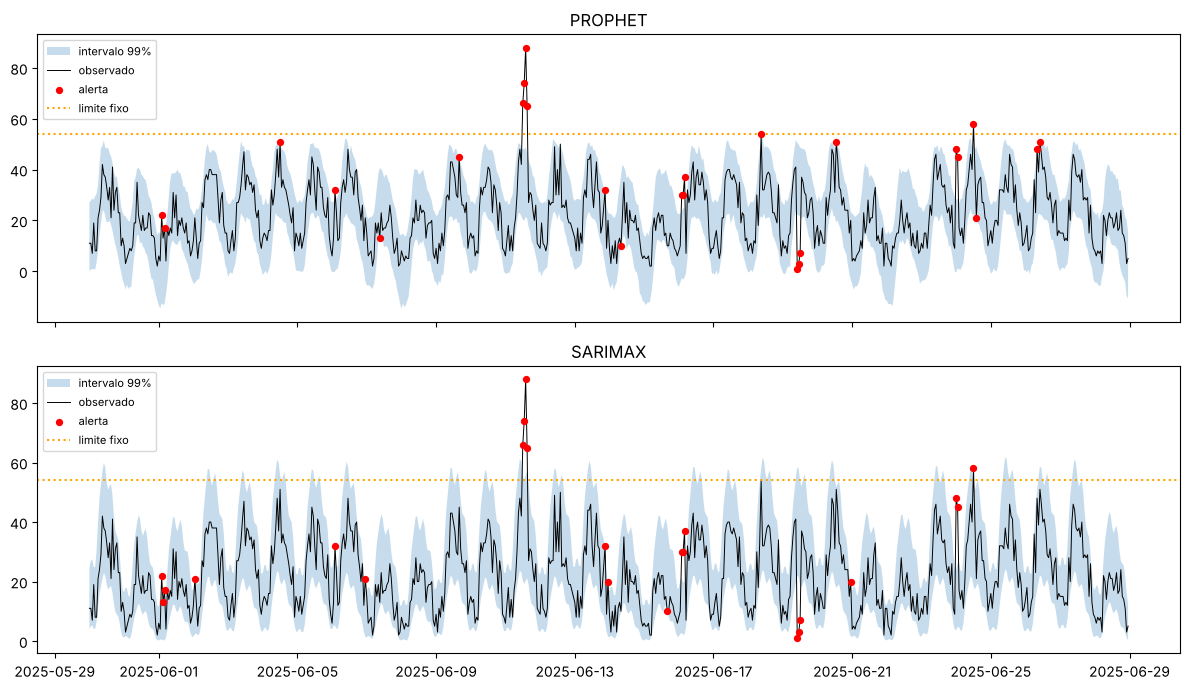

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, nome in zip(axs, ['prophet', 'sarimax']):
    ax.fill_between(teste['ds'], teste[f'inf_{nome}'], teste[f'sup_{nome}'], alpha=0.25, label='intervalo 99%')
    ax.plot(teste['ds'], teste['y'], lw=0.7, c='k', label='observado')
    al = teste[teste[f'alerta_{nome}'] == 1]
    ax.scatter(al['ds'], al['y'], c='red', s=18, label='alerta', zorder=3)
    ax.axhline(lim_sup, c='orange', ls=':', label='limite fixo')
    ax.set_title(nome.upper()); ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

## Conclusões

- O **limite fixo** ignora a sazonalidade. Ele precisa ser alto para não disparar nos picos normais do horário comercial e, por isso, deixa passar quase todas as anomalias que acontecem em horários calmos e as quedas.
- **Prophet** e **SARIMAX** aprendem o padrão por hora e dia da semana e alertam quando o valor sai do esperado *para aquele momento*. Os dois pegaram a grande maioria das anomalias.
- No SARIMAX, **estabilizar a variância** com raiz quadrada fez toda a diferença: sem ela, o recall ficava abaixo de 30%.
- O Prophet é mais prático para várias sazonalidades e feriados. O SARIMAX dá mais controle estatístico sobre o modelo.

**Limitações e próximos passos**
- Os dados são sintéticos e as anomalias foram injetadas, o que permite medir precision e recall. Em dados reais, quase nunca existe esse gabarito pronto.
- O intervalo de 99% é um parâmetro de negócio: mais largo gera menos alarme falso e mais anomalias perdidas.
- Próximos passos: reajustar o modelo periodicamente (janela móvel), tratar feriados e agrupar alertas consecutivos em um único evento.